# Titanic Survival Prediction
End-to-end ML workflow: data loading → exploration → EDA → preprocessing → feature engineering → model training → model evaluation.

**Dataset:** `titanic.csv` (891 passengers, target = `Survived`). Place the CSV next to this notebook, or edit `DATA_PATH` below.

## 0. Setup

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42
DATA_PATH = "titanic.csv"   # change if the file is elsewhere

## 1. Data Loading

In [ ]:
df = pd.read_csv(content_path)
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Gender,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Data Exploration

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Gender       891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
missing = pd.DataFrame({"missing": df.isna().sum(), "pct": (df.isna().mean()*100).round(1)})
missing[missing.missing > 0]

,missing,pct
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [9]:
df.describe(include='object').T

,count,unique,top,freq
Name,891,891,"Dooley, Mr. Patrick",1
Gender,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


In [10]:
print("Duplicate rows:", df.duplicated().sum())
print("\nTarget balance:")
print(df.Survived.value_counts(normalize=True).round(3))

Duplicate rows: 0

Target balance:
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


**Observations**
- `Cabin` is ~77% missing, `Age` ~20% missing, `Embarked` has 2 missing values.
- Target is moderately imbalanced (≈38% survived).

## 3. Exploratory Data Analysis (EDA)

In [11]:
for col in ["Gender", "Pclass", "Embarked", "SibSp", "Parch"]:
    print(f"\nSurvival rate by {col}")
    print(df.groupby(col).Survived.agg(["mean", "count"]).round(3))


Survival rate by Gender
         mean  count
Gender              
female  0.742    314
male    0.189    577

Survival rate by Pclass
         mean  count
Pclass              
1       0.630    216
2       0.473    184
3       0.242    491

Survival rate by Embarked
           mean  count
Embarked              
C         0.554    168
Q         0.390     77
S         0.337    644

Survival rate by SibSp
        mean  count
SibSp              
0      0.345    608
1      0.536    209
2      0.464     28
3      0.250     16
4      0.167     18
5      0.000      5
8      0.000      7

Survival rate by Parch
        mean  count
Parch              
0      0.344    678
1      0.551    118
2      0.500     80
3      0.600      5
4      0.000      4
5      0.200      5
6      0.000      1


In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
sns.countplot(data=df, x="Survived", ax=ax[0,0]);                        ax[0,0].set_title("Survival counts")
sns.barplot(data=df, x="Gender", y="Survived", ax=ax[0,1]);              ax[0,1].set_title("Survival rate by gender")
sns.barplot(data=df, x="Pclass", y="Survived", ax=ax[0,2]);              ax[0,2].set_title("Survival rate by class")
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, ax=ax[1,0]); ax[1,0].set_title("Age distribution")
sns.boxplot(data=df, x="Pclass", y="Fare", ax=ax[1,1]); ax[1,1].set_yscale("log"); ax[1,1].set_title("Fare by class (log scale)")
sns.barplot(data=df, x="Embarked", y="Survived", ax=ax[1,2]);            ax[1,2].set_title("Survival rate by port")
plt.tight_layout(); plt.show()

In [ ]:
plt.figure(figsize=(7, 4.5))
sns.barplot(data=df, x="Pclass", y="Survived", hue="Gender")
plt.title("Survival rate by class and gender"); plt.show()

**Key EDA findings**
- Gender is the strongest signal: ~74% of women survived vs ~19% of men.
- Survival drops with class: 63% (1st) → 47% (2nd) → 24% (3rd).
- Cherbourg passengers survived more often (likely more 1st-class passengers).
- Small families did better than solo travellers or very large families.

## 4. Data Preprocessing & 5. Feature Engineering

### 4a. Feature engineering (done first so `Title` can help impute `Age`)

In [12]:
d = df.copy()

# Title from name
d["Title"] = d.Name.str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
d["Title"] = d.Title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
rare = d.Title.value_counts()[lambda s: s < 10].index
d["Title"] = d.Title.replace(list(rare), "Rare")

# Family / cabin / ticket features
d["FamilySize"]      = d.SibSp + d.Parch + 1
d["IsAlone"]         = (d.FamilySize == 1).astype(int)
d["HasCabin"]        = d.Cabin.notna().astype(int)
d["Deck"]            = d.Cabin.str[0].fillna("U")
d["TicketGroupSize"] = d.groupby("Ticket").Ticket.transform("count")

d.Title.value_counts()

,count
Title,
Mr,517
Miss,185
Mrs,126
Master,40
Rare,23


### 4b. Handle missing values

In [13]:
# Age: median within (Title, Pclass) groups, global median as fallback
d["Age"] = d.groupby(["Title", "Pclass"]).Age.transform(lambda s: s.fillna(s.median()))
d["Age"] = d.Age.fillna(d.Age.median())

# Embarked: mode
d["Embarked"] = d.Embarked.fillna(d.Embarked.mode()[0])

d[["Age", "Embarked"]].isna().sum()

,0
Age,0
Embarked,0


### 4c. Derived features that need clean Age

In [14]:
d["FarePerPerson"]   = d.Fare / d.TicketGroupSize
d["FareLog"]         = np.log1p(d.Fare)
d["AgeBin"]          = pd.cut(d.Age, [0, 12, 18, 35, 60, 100],
                              labels=["Child", "Teen", "YoungAdult", "Adult", "Senior"])
d["Women_Children"]  = ((d.Gender == "female") | (d.Age < 13)).astype(int)

### 4d. Encoding & dropping unused columns

In [15]:
d["Gender"] = (d.Gender == "male").astype(int)      # 1 = male
d["Deck"]   = d.Deck.replace({"T": "U"})            # single 'T' deck → unknown
d = pd.get_dummies(d, columns=["Embarked", "Title", "Deck", "AgeBin"], drop_first=True, dtype=int)
d = d.drop(columns=["PassengerId", "Name", "Ticket", "Cabin", "Fare"])

y = d.pop("Survived")
X = d
print("Feature matrix:", X.shape, "| remaining nulls:", int(X.isna().sum().sum()))
print(list(X.columns))

Feature matrix: (891, 29) | remaining nulls: 0
['Pclass', 'Gender', 'Age', 'SibSp', 'Parch', 'FamilySize', 'IsAlone', 'HasCabin', 'TicketGroupSize', 'FarePerPerson', 'FareLog', 'Women_Children', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'Deck_B', 'Deck_C', 'Deck_D', 'Deck_E', 'Deck_F', 'Deck_G', 'Deck_U', 'AgeBin_Teen', 'AgeBin_YoungAdult', 'AgeBin_Adult', 'AgeBin_Senior']


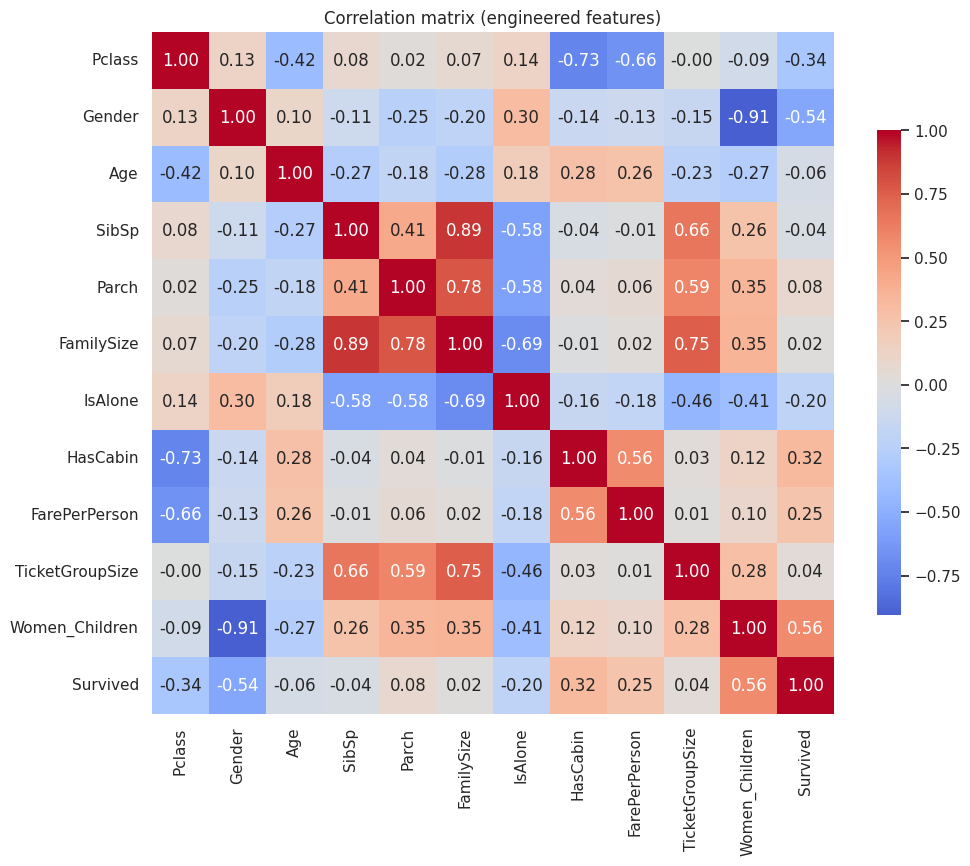

,Survived
Gender,-0.543
Pclass,-0.338
IsAlone,-0.203
Age,-0.063
SibSp,-0.035
FamilySize,0.017
TicketGroupSize,0.038
Parch,0.082
FarePerPerson,0.255
HasCabin,0.317


In [16]:
num_cols = ["Pclass", "Gender", "Age", "SibSp", "Parch", "FamilySize", "IsAlone",
            "HasCabin", "FarePerPerson", "TicketGroupSize", "Women_Children"]
corr = pd.concat([X[num_cols], y], axis=1).corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Correlation matrix (engineered features)"); plt.show()

corr.Survived.drop("Survived").sort_values().round(3)

### 4e. Train / test split

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (712, 29) | Test: (179, 29)


## 6. Model Training

### 6a. Baseline comparison (5-fold stratified CV)

Logistic Regression    CV accuracy = 0.8175 ± 0.0350
KNN                    CV accuracy = 0.8118 ± 0.0203
SVM (RBF)              CV accuracy = 0.8161 ± 0.0315
Random Forest          CV accuracy = 0.8231 ± 0.0139
Gradient Boosting      CV accuracy = 0.8231 ± 0.0316


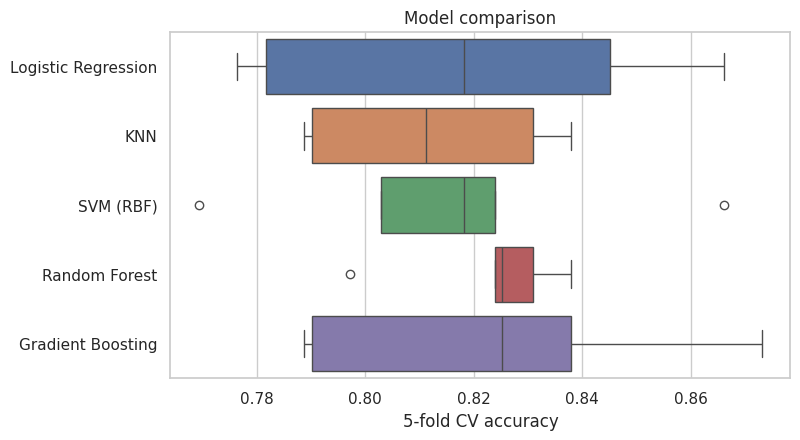

In [18]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(probability=True, random_state=RANDOM_STATE)),
    "Random Forest":       RandomForestClassifier(300, random_state=RANDOM_STATE),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
}
cv_res = {}
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="accuracy")
    cv_res[name] = s
    print(f"{name:22s} CV accuracy = {s.mean():.4f} ± {s.std():.4f}")

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=pd.DataFrame(cv_res), orient="h")
plt.xlabel("5-fold CV accuracy"); plt.title("Model comparison"); plt.show()

### 6b. Hyperparameter tuning (Random Forest & Gradient Boosting)

In [20]:
rf_gs = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    {"n_estimators": [200, 400], "max_depth": [4, 6, 8, None], "min_samples_leaf": [1, 3, 5]},
    cv=cv, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)

gb_gs = GridSearchCV(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    {"n_estimators": [100, 200], "learning_rate": [0.03, 0.1],
     "max_depth": [2, 3, 4], "subsample": [0.8, 1.0]},
    cv=cv, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)

print("RF best:", rf_gs.best_params_, f"CV = {rf_gs.best_score_:.4f}")
print("GB best:", gb_gs.best_params_, f"CV = {gb_gs.best_score_:.4f}")

RF best: {'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 200} CV = 0.8372
GB best: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 200, 'subsample': 0.8} CV = 0.8357


In [21]:
final = {
    "Logistic Regression":       models["Logistic Regression"].fit(X_train, y_train),
    "SVM (RBF)":                 models["SVM (RBF)"].fit(X_train, y_train),
    "Random Forest (tuned)":     rf_gs.best_estimator_,
    "Gradient Boosting (tuned)": gb_gs.best_estimator_,
}

## 7. Model Evaluation (held-out test set)

In [22]:
rows = []
for name, m in final.items():
    pred = m.predict(X_test); proba = m.predict_proba(X_test)[:, 1]
    rows.append(dict(Model=name,
                     Accuracy=accuracy_score(y_test, pred),
                     Precision=precision_score(y_test, pred),
                     Recall=recall_score(y_test, pred),
                     F1=f1_score(y_test, pred),
                     ROC_AUC=roc_auc_score(y_test, proba)))
res = pd.DataFrame(rows).set_index("Model").round(4).sort_values("ROC_AUC", ascending=False)
res

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.8156,0.7647,0.7536,0.7591,0.8626
Random Forest (tuned),0.7933,0.7667,0.6667,0.7132,0.8551
Gradient Boosting (tuned),0.7989,0.7619,0.6957,0.7273,0.8514
SVM (RBF),0.8045,0.7361,0.7681,0.7518,0.8423


In [23]:
best_name = res.index[0]; best = final[best_name]
print("Best model by ROC-AUC:", best_name, "\n")
print(classification_report(y_test, best.predict(X_test), target_names=["Died", "Survived"]))

Best model by ROC-AUC: Logistic Regression 

              precision    recall  f1-score   support

        Died       0.85      0.85      0.85       110
    Survived       0.76      0.75      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.82      0.82      0.82       179



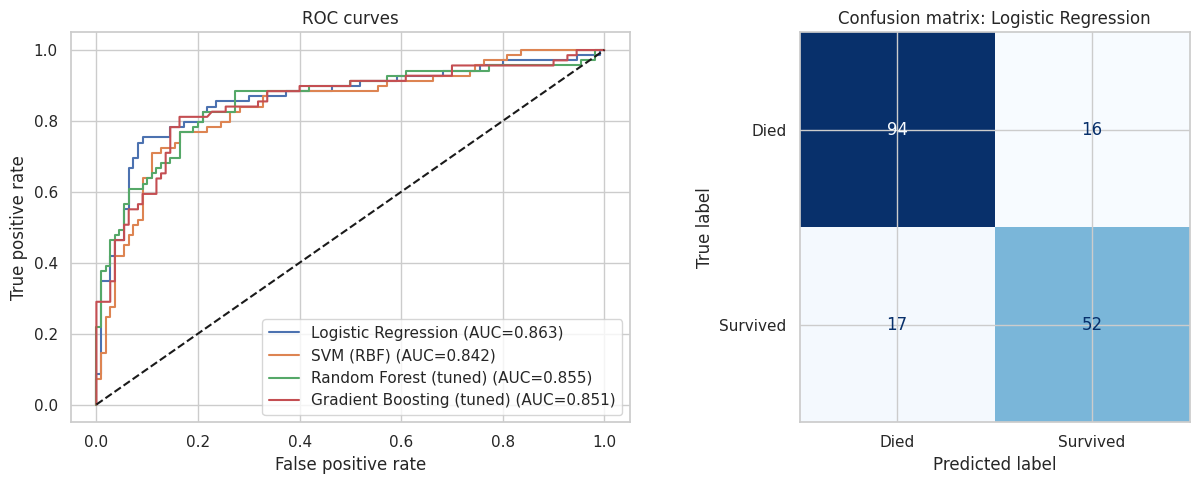

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, m in final.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={res.loc[name, 'ROC_AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--")
ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves")
ax[0].legend(loc="lower right")

ConfusionMatrixDisplay(confusion_matrix(y_test, best.predict(X_test)),
                       display_labels=["Died", "Survived"]).plot(ax=ax[1], cmap="Blues", colorbar=False)
ax[1].set_title(f"Confusion matrix: {best_name}")
plt.tight_layout(); plt.show()

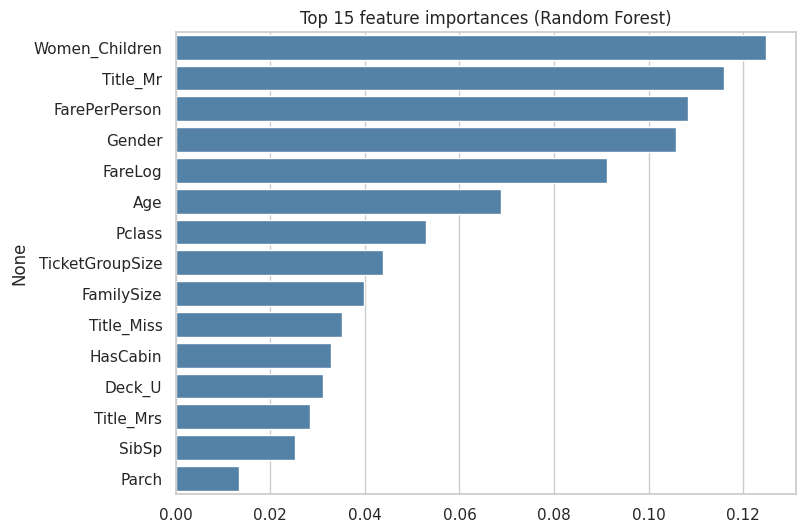

In [25]:
imp = (pd.Series(final["Random Forest (tuned)"].feature_importances_, index=X.columns)
         .sort_values(ascending=False).head(15))
plt.figure(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index, color="steelblue")
plt.title("Top 15 feature importances (Random Forest)"); plt.show()

## Conclusions
- All models land at roughly **80–82% test accuracy** and **0.84–0.86 ROC-AUC**; differences are within noise on a 179-row test set.
- **Logistic regression** scored best on the test set (accuracy ≈ 0.816, ROC-AUC ≈ 0.863).
- Most important features: `Women_Children`, `Title_Mr`, `FarePerPerson`, `Gender`; two of these are engineered.
- Possible next steps: surname-based family-survival features, ensembling/stacking, repeated CV for a more stable comparison.